# Notebook 06 — RQ3 (Compare): Did interest in Germany grow after the reforms?

**Project:** Searching for Work in Germany: Google Trends Signals of Labour Migration Interest and Policy Effects (focus: migrant care workers)
**Author:** Tayaphon Rodsai · MSc Data Science for Society and Business, Constructor University

---

### The question

> **RQ3:** Did interest in working in Germany, especially in care jobs, grow after the 2023–2024 reforms, compared with interest in other destinations (Canada, UK, Australia, Japan)?

### The reforms (Skilled Immigration Act, *Fachkräfteeinwanderungsgesetz*)

| Date | Step | Why it matters for care workers |
|---|---|---|
| 18 Nov 2023 | Stage 1: easier Blue Card and skilled-worker rules | general signal "Germany is opening" |
| **1 Mar 2024** | Stage 2: **recognition partnership** (*Anerkennungspartnerschaft*): work first, recognise the diploma in Germany | **most direct for foreign nurses** → our main date |
| 1 Jun 2024 | Stage 3: **Opportunity Card** (*Chancenkarte*) | job search visa |

### The idea: difference-in-differences (DiD)

If "nurse germany" goes up after March 2024, that alone proves little: maybe **all** nursing-abroad searches went up (e.g. after COVID). So we compare **Germany** with **other destinations in the same country**:

1. **Gap** = interest in Germany − average interest in the other destinations (each month).
2. **DiD** = gap **after** the reform − gap **before** the reform.

If Germany gained **more** than the others, the gap grows → DiD > 0.

We use **log(1 + interest)**, so the gap is about *relative* (percentage) differences: a DiD of 0.3 means Germany grew about exp(0.3) − 1 ≈ **35% more** than the other destinations.

**Key assumption ("parallel trends"):** without the reform, the gap would have stayed the same. We test this in section 6.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

RAW = Path("../data/raw/rq3")
PROCESSED = Path("../data/processed")
FIGURES = Path("../reports/figures")

CODES = {"PH": "Philippines", "IN": "India", "VN": "Viet Nam", "ID": "Indonesia"}
START = "2022-01-01"                     # after Google's data change in Jan 2022
REFORMS = {"stage 1 (Nov 2023)": "2023-11-01",
           "stage 2 (Mar 2024)": "2024-03-01",   # main date
           "stage 3 (Jun 2024)": "2024-06-01"}
MAIN = REFORMS["stage 2 (Mar 2024)"]
MAX_ZERO_SHARE = 35                      # same 'usable' rule as Notebook 02

# Last word(s) of each search term → destination
DESTINATIONS = {
    "germany": ["germany", "jerman", "đức"],
    "canada": ["canada", "kanada"],
    "uk": ["uk", "inggris", "quốc"],          # 'anh quốc' ends with 'quốc'
    "australia": ["australia", "úc"],
    "japan": ["japan", "jepang", "nhật"],
}
def destination(term):
    last = term.lower().split()[-1]
    return next(d for d, words in DESTINATIONS.items() if last in words)

## 2. Load the data and decide which terms to use

**Settings:** Google Trends · search term · whole country · 1 Jan 2022 – 31 Oct 2026 · all categories · web search · monthly · downloaded 20 Nov 2026 (see `data/raw/rq3/download_log.txt`).

All five terms of one country come from **one request**, so they share the same 0–100 scale. We never compare values between countries here.

| Origin | Germany | Canada | UK | Australia | Japan |
|---|---|---|---|---|---|
| PH | nurse germany | nurse canada | nurse uk | nurse australia | nurse japan |
| IN | nurse germany | nurse canada | nurse uk | nurse australia | nurse japan |
| VN | điều dưỡng đức | điều dưỡng canada | điều dưỡng anh quốc | điều dưỡng úc | điều dưỡng nhật |
| ID | perawat jerman | perawat kanada | perawat inggris | perawat australia | perawat jepang |

**Choices made before the analysis**
- **India** uses "nurse + country" like the Philippines. The Notebook 02 seed *nursing jobs in germany* was too rare (57% zeros since 2022); India's related queries contain *nurse salary in germany* and *germany nurse salary*.
- **Viet Nam:** *điều dưỡng anh* was replaced by *điều dưỡng anh quốc*, because "anh" also means "English" or "older brother" (average fell from 57 to 5 after the change). *nhật bản* was replaced by *nhật*, the usual short form.
- **Indonesia:** the UK term (*perawat inggris*) was **excluded**, because its related queries refer mainly to the English language (*bahasa inggris*, *perawat bahasa inggris*, translation), not to the UK.
- A term with **more than 35% zero months** is excluded (same rule as Notebook 02).

In [2]:
EXCLUDED_BY_MEANING = {("ID", "uk"): "related queries are about the English language, not the UK"}

frames = []
for code in CODES:
    data = pd.read_csv(RAW / f"{code}_care.csv", parse_dates=["Time"]).set_index("Time")
    data = data[data.index >= START]                      # PH and IN files start in Dec 2021
    for term in data.columns:
        frames.append(pd.DataFrame({"code": code, "destination": destination(term), "term": term,
                                    "month": data.index, "interest": data[term].values}))
panel = pd.concat(frames, ignore_index=True)

decisions = (panel.groupby(["code", "destination", "term"])["interest"]
                  .agg(mean="mean", zero_share=lambda s: (s == 0).mean() * 100)
                  .round(0).reset_index())
def decide(row):
    if (row["code"], row["destination"]) in EXCLUDED_BY_MEANING:
        return "excluded: " + EXCLUDED_BY_MEANING[(row["code"], row["destination"])]
    if row["zero_share"] > MAX_ZERO_SHARE:
        return f"excluded: too rare ({row['zero_share']:.0f}% zero months)"
    return "kept"
decisions["decision"] = decisions.apply(decide, axis=1)
decisions

,code,destination,term,mean,zero_share,decision
0,ID,australia,perawat australia,4.0,41.0,excluded: too rare (41% zero months)
1,ID,canada,perawat kanada,0.0,100.0,excluded: too rare (100% zero months)
2,ID,germany,perawat jerman,12.0,3.0,kept
3,ID,japan,perawat jepang,50.0,0.0,kept
4,ID,uk,perawat inggris,49.0,0.0,excluded: related queries are about the Englis...
5,IN,australia,nurse australia,39.0,0.0,kept
6,IN,canada,nurse canada,34.0,0.0,kept
7,IN,germany,nurse germany,25.0,0.0,kept
8,IN,japan,nurse japan,25.0,0.0,kept
9,IN,uk,nurse UK,52.0,0.0,kept


In [3]:
kept = decisions.loc[decisions["decision"] == "kept", ["code", "destination"]]
panel = panel.merge(kept, on=["code", "destination"])
panel["log_interest"] = np.log1p(panel["interest"])
panel.groupby("code")["destination"].unique().apply(list)

code
ID                           [germany, japan]
IN    [germany, canada, uk, japan, australia]
PH    [germany, canada, uk, japan, australia]
VN                [germany, australia, japan]
Name: destination, dtype: object

**What is left:** the Philippines and India keep all four comparison destinations. **Viet Nam** keeps Japan and Australia; **Indonesia** only Japan. So the VN and ID results rest on fewer comparisons.

## 3. Look at the data first

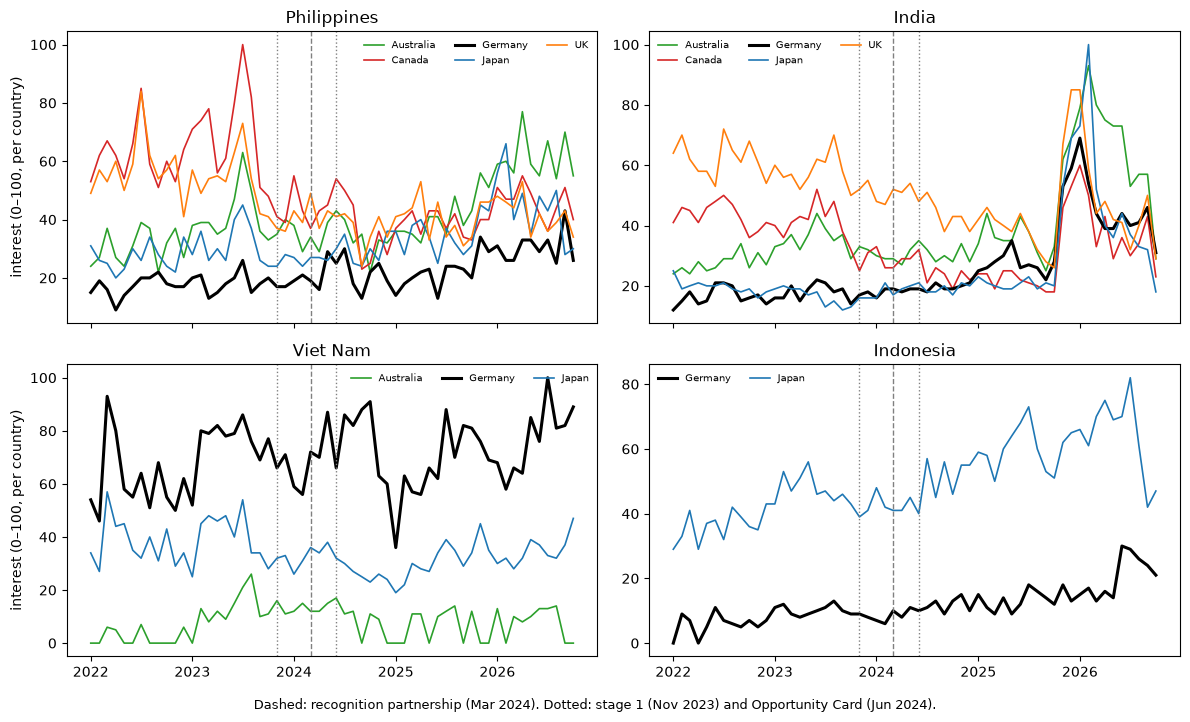

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
colors = {"germany": "black", "canada": "C3", "uk": "C1", "australia": "C2", "japan": "C0"}
for ax, (code, part) in zip(axes.flat, panel.groupby("code", sort=False)):
    for dest, s in part.groupby("destination"):
        ax.plot(s["month"], s["interest"], color=colors[dest], lw=2.2 if dest == "germany" else 1.2,
                label=dest.capitalize() if dest != "uk" else "UK")
    for date in REFORMS.values():
        ax.axvline(pd.Timestamp(date), color="grey", ls=":" if date != MAIN else "--", lw=1)
    ax.set_title(CODES[code])
    ax.legend(frameon=False, fontsize=7, ncol=3)
axes[0, 0].set_ylabel("interest (0–100, per country)")
axes[1, 0].set_ylabel("interest (0–100, per country)")
fig.text(0.5, -0.02, "Dashed: recognition partnership (Mar 2024). Dotted: stage 1 (Nov 2023) and Opportunity Card (Jun 2024).",
         ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / "06_rq3_destinations.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. The gap: Germany compared with the other destinations

Gap = log(1 + Germany) − average log(1 + other destinations). A rising gap means Germany gains **relative to** the others.

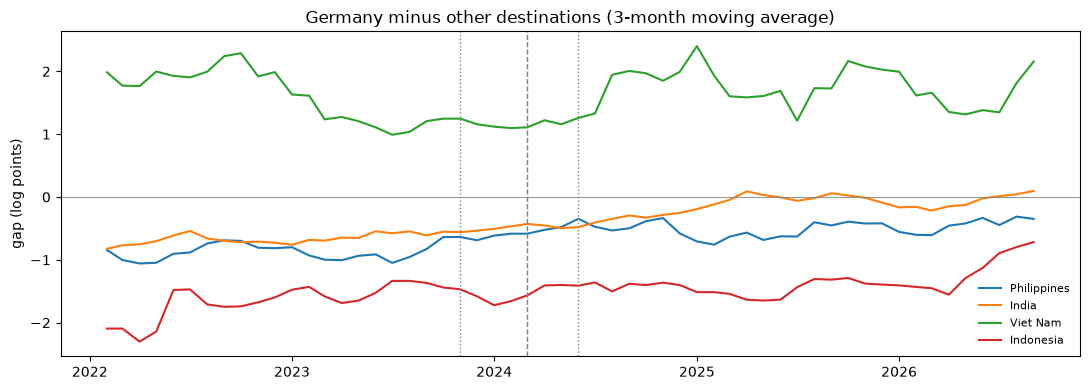

,PH,IN,VN,ID
month,,,,
2022,-0.86,-0.72,1.97,-1.91
2023,-0.86,-0.61,1.28,-1.47
2024,-0.48,-0.40,1.51,-1.48
2025,-0.57,-0.03,1.84,-1.46
2026,-0.44,-0.05,1.68,-1.13


In [5]:
def gap_series(code, controls=None):
    wide = panel[panel["code"] == code].pivot(index="month", columns="destination", values="log_interest")
    others = [d for d in wide.columns if d != "germany" and (controls is None or d in controls)]
    return wide["germany"] - wide[others].mean(axis=1)

gaps = pd.DataFrame({code: gap_series(code) for code in CODES})

fig, ax = plt.subplots(figsize=(11, 4))
for code in CODES:
    ax.plot(gaps.index, gaps[code].rolling(3, center=True).mean(), label=CODES[code])
for date in REFORMS.values():
    ax.axvline(pd.Timestamp(date), color="grey", ls=":" if date != MAIN else "--", lw=1)
ax.axhline(0, color="grey", lw=0.6)
ax.set_ylabel("gap (log points)")
ax.set_title("Germany minus other destinations (3-month moving average)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(FIGURES / "06_rq3_gap.png", dpi=150, bbox_inches="tight")
plt.show()

gaps.groupby(gaps.index.year).mean().round(2)

## 5. Main result: difference-in-differences per country

For each country we estimate: **gap = a + DiD × after_reform**.

- `after_reform` = 1 from March 2024, else 0.
- Monthly data are **autocorrelated** (one month looks like the next), which makes normal standard errors too small. So we use **HAC (Newey–West) standard errors** with 6 lags.
- `pct` = exp(DiD) − 1: how much more Germany grew than the others, in %.

In [6]:
def did(gap, start=MAIN, trend=False, data_end=None):
    d = gap.dropna().to_frame("gap")
    if data_end is not None:
        d = d[d.index < data_end]
    d["after"] = (d.index >= start).astype(int)
    d["t"] = np.arange(len(d))
    formula = "gap ~ after + t" if trend else "gap ~ after"
    m = smf.ols(formula, d).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    lo, hi = m.conf_int().loc["after"]
    return {"did": m.params["after"], "ci_low": lo, "ci_high": hi, "p": m.pvalues["after"],
            "pct": (np.exp(m.params["after"]) - 1) * 100, "months": len(d)}

main = pd.DataFrame({CODES[c]: did(gaps[c]) for c in CODES}).T
main.round(3)

,did,ci_low,ci_high,p,pct,months
Philippines,0.344,0.219,0.469,0.000,41.082,58.0
India,0.511,0.343,0.679,0.000,66.669,58.0
Viet Nam,0.136,-0.258,0.530,0.498,14.563,58.0
Indonesia,0.354,0.079,0.629,0.012,42.470,58.0


## 6. Can we trust it? Five checks

| Check | Question | Good sign |
|---|---|---|
| **A. Pre-trend** | Was the gap already moving *before* March 2024? | slope ≈ 0 |
| **B. Placebo date** | With a fake reform in March 2023 (before data only), do we also find an "effect"? | no effect |
| **C. Other reform dates** | Same result with Nov 2023 or Jun 2024? | similar DiD |
| **D. Without UK and Canada** | Both changed their own rules (Canada cut numbers in 2024; UK closed the care-worker visa in July 2025). Does the result hold with Japan and Australia only? | similar DiD |
| **E. With a time trend** | If we allow the gap to have its own trend, is there still a jump? | DiD stays > 0 |

In [7]:
checks = []
for code in CODES:
    gap = gaps[code]
    pre = gap[gap.index < MAIN].dropna().to_frame("gap")
    pre["t"] = np.arange(len(pre))
    trend_model = smf.ols("gap ~ t", pre).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    placebo = did(gap, start="2023-03-01", data_end=MAIN)
    row = {"country": CODES[code],
           "A pre-trend per year": trend_model.params["t"] * 12,
           "A p": trend_model.pvalues["t"],
           "B placebo DiD": placebo["did"], "B p": placebo["p"],
           "C Nov 2023": did(gap, start=REFORMS["stage 1 (Nov 2023)"])["did"],
           "C Jun 2024": did(gap, start=REFORMS["stage 3 (Jun 2024)"])["did"]}
    no_uk_ca = gap_series(code, controls=["japan", "australia"])
    d_ = did(no_uk_ca)
    row["D Japan+Australia"], row["D p"] = d_["did"], d_["p"]
    e_ = did(gap, trend=True)
    row["E with trend"], row["E p"] = e_["did"], e_["p"]
    checks.append(row)
checks = pd.DataFrame(checks).set_index("country")
checks.round(3)

,A pre-trend per year,A p,B placebo DiD,B p,C Nov 2023,C Jun 2024,D Japan+Australia,D p,E with trend,E p
country,,,,,,,,,,
Philippines,0.107,0.072,0.023,0.839,0.369,0.314,0.072,0.190,0.161,0.162
India,0.141,0.000,0.157,0.000,0.498,0.522,0.183,0.002,0.098,0.265
Viet Nam,-0.587,0.000,-0.784,0.000,-0.020,0.224,0.136,0.498,0.426,0.258
Indonesia,0.328,0.029,0.281,0.110,0.332,0.331,0.354,0.012,-0.211,0.348


## 7. Findings

*(numbers from the cells above; download of 20 Nov 2026)*

1. **Simple DiD: Germany gained relative to the other destinations in the Philippines (+0.34), India (+0.51) and Indonesia (+0.35)** after March 2024 (about 40–65% more growth than the others; p < 0.05). In **Viet Nam** there is **no clear change** (+0.14, p = 0.50): Germany was already the top nursing destination there.
2. **The exact reform date does not matter much** (Nov 2023, Mar 2024 and Jun 2024 give similar values, check C).
3. **But none of the three positive results passes all checks:**
   - **Philippines:** no clear pre-trend and no placebo effect ✅, but **with Japan and Australia only, the effect almost disappears** (0.07, p = 0.19). So the Philippine gain comes mainly from **Canada and the UK falling**, not from Germany rising faster than Japan or Australia.
   - **India:** Germany was **already gaining before** the reform (pre-trend p < 0.001; placebo also "significant").
   - **Indonesia:** also a **pre-trend** (p = 0.03); there is only one comparison destination (Japan).
4. **With a time trend (check E), no country shows a significant jump.** The data fit a **steady rise of Germany since 2022** better than a sudden jump at the reform.
5. **Answer to RQ3 (careful):** Interest in nursing in Germany **grew relative to other destinations** in three of four countries, and the timing overlaps with the 2023–2024 reforms. But we **cannot attribute this to the reforms**: the rise started earlier (e.g. recruitment programmes such as Triple Win, the 2020 Skilled Immigration Act), and part of it reflects **Canada and the UK becoming less attractive** at the same time.

### Limitations
- **Short "before" period** (Jan 2022 – Feb 2024, 26 months), because we start after Google's data change in January 2022.
- **The comparison destinations also changed** (Canada 2024, UK July 2025), so they are not a clean "untreated" group. Check D shows this matters for the Philippines.
- **Few comparisons in VN and ID** (Japan, plus Australia in VN); several terms were too rare or had other meanings. For ID, check D is the same as the main result (no UK or Canada).
- **log(1 + x)** makes changes from small values (e.g. Germany in Indonesia, 6 → 20) look large.
- **Searches ≠ migration:** a search shows interest, not a decision or a visa.
- **Only 4 countries and one theme (care).** A work theme for all 9 countries is future work.


## 8. Save

In [8]:
decisions.to_csv(PROCESSED / "rq3_keyword_decisions.csv", index=False)
main.to_csv(PROCESSED / "rq3_did_main.csv")
checks.to_csv(PROCESSED / "rq3_did_checks.csv")
print("Saved to", PROCESSED.resolve())

Saved to C:\Users\Tayami\Downloads\F26_MDSSB-CAP-01_Capstone Project\data\processed
